# Data loading

In [9]:
from pathlib import Path
import re
import numpy as np
import rasterio
from rasterio.windows import Window
from rasterio.transform import from_origin
from pyresample import geometry, kd_tree
import matplotlib.pyplot as plt

DATA = Path("../data")
OUT = Path("../outputs"); OUT.mkdir(exist_ok=True)

STRIPS = ["M3G20090205T111013", "M3G20090205T092400"]   # primary strip first

# Apollo 15 landing site and subset box (degrees)
SITE_LAT, SITE_LON = 26.132, 3.634
LAT_MIN, LAT_MAX = 25.4, 26.9
LON_MIN, LON_MAX = 2.8, 4.05     # tightened to what the primary strip fully covers
RES = 0.0045                     # output grid, ~140 m/pixel

def find(strip, kind, ext="img"):
    """Locate e.g. the RFL .IMG for a strip anywhere under data/."""
    hits = [p for p in DATA.rglob(f"{strip}_*_{kind}.*")
            if p.suffix.lower() == f".{ext}"]
    if not hits:
        raise FileNotFoundError(f"{strip} {kind}.{ext} not found in {DATA}")
    return hits[0]

In [10]:
for strip in STRIPS:
    print(strip)
    for kind in ["RFL", "SUP", "LOC", "OBS"]:
        with rasterio.open(find(strip, kind)) as src:
            print(f"  {kind}: bands={src.count:3d}  lines={src.height}  "
                  f"samples={src.width}  dtype={src.dtypes[0]}")

M3G20090205T111013
  RFL: bands= 85  lines=13822  samples=304  dtype=float32
  SUP: bands=  3  lines=13822  samples=304  dtype=float32
  LOC: bands=  3  lines=13822  samples=304  dtype=float64
  OBS: bands= 10  lines=13822  samples=304  dtype=float32
M3G20090205T092400
  RFL: bands= 85  lines=13197  samples=304  dtype=float32
  SUP: bands=  3  lines=13197  samples=304  dtype=float32
  LOC: bands=  3  lines=13197  samples=304  dtype=float64
  OBS: bands= 10  lines=13197  samples=304  dtype=float32


/Users/sourabh/Documents/python_codes/m3_spectral_clustering/.venv/lib/python3.13/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


In [11]:
def read_wavelengths(strip):
    text = find(strip, "RFL", ext="hdr").read_text()
    m = re.search(r"wavelength\s*=\s*\{([^}]*)\}", text, re.I)
    return np.array([float(v) for v in m.group(1).split(",")])

wl = read_wavelengths(STRIPS[0])
print(len(wl), "bands:", wl[0], "to", wl[-1])

85 bands: 460.99 to 2976.2


# Subset image to Mons Hadley

In [12]:
def load_subset(strip):
    with rasterio.open(find(strip, "LOC")) as src:
        lon, lat = src.read(1), src.read(2)
    lon = ((lon + 180) % 360) - 180                 # force -180..180

    in_box = (lat > LAT_MIN) & (lat < LAT_MAX) & (lon > LON_MIN) & (lon < LON_MAX)
    rows = np.where(in_box.any(axis=1))[0]
    if rows.size == 0:
        print(f"{strip}: does not cross the box")
        return None
    r0, r1 = rows.min(), rows.max() + 1
    win = Window(0, r0, lon.shape[1], r1 - r0)       # col_off, row_off, width, height

    with rasterio.open(find(strip, "RFL")) as src:
        rfl = src.read(window=win)                   # (85, lines, 304)
    with rasterio.open(find(strip, "OBS")) as src:
        obs = src.read(window=win)                   # (10, lines, 304)
    rfl = np.where(rfl < -900, np.nan, rfl)          # -999 = no data

    lon, lat = lon[r0:r1], lat[r0:r1]
    d_km = np.hypot(lat - SITE_LAT,
                    (lon - SITE_LON) * np.cos(np.radians(SITE_LAT))).min() * 30.3
    print(f"{strip}: lines {r0}-{r1}, rfl {rfl.shape}, "
          f"nearest pixel to landing site = {d_km:.2f} km")
    return dict(strip=strip, lon=lon, lat=lat, rfl=rfl, obs=obs)

subsets = [s for s in (load_subset(s) for s in STRIPS) if s is not None]

M3G20090205T111013: lines 12274-12571, rfl (85, 297, 304), nearest pixel to landing site = 0.03 km
M3G20090205T092400: lines 5294-5591, rfl (85, 297, 304), nearest pixel to landing site = 0.04 km


# Georeferencing (Save files)

In [13]:
MOON = {"proj": "longlat", "R": 1737400, "no_defs": True}
WIDTH  = int(round((LON_MAX - LON_MIN) / RES))
HEIGHT = int(round((LAT_MAX - LAT_MIN) / RES))
AREA = geometry.AreaDefinition("a15", "", "", MOON, WIDTH, HEIGHT,
                               (LON_MIN, LAT_MIN, LON_MAX, LAT_MAX))

# pyresample measures search distances on an Earth-sized sphere,
# so scale the lunar radius up by R_earth / R_moon (~3.67)
EARTH_R, MOON_R = 6370997.0, 1737400.0
RADIUS = 200 * EARTH_R / MOON_R      # 200 m on the Moon

def georeference(sub, key="rfl"):
    swath = geometry.SwathDefinition(lons=sub["lon"], lats=sub["lat"])
    data = np.moveaxis(sub[key], 0, -1)              # (lines, samples, bands)
    out = kd_tree.resample_nearest(swath, data, AREA,
                                   radius_of_influence=RADIUS, fill_value=np.nan)
    return np.moveaxis(out, -1, 0).astype("float32") # (bands, HEIGHT, WIDTH)

def save_geotiff(cube, path):
    with rasterio.open(path, "w", driver="GTiff", width=WIDTH, height=HEIGHT,
                       count=cube.shape[0], dtype="float32", nodata=np.nan,
                       crs="+proj=longlat +R=1737400 +no_defs",
                       transform=from_origin(LON_MIN, LAT_MAX, RES, RES)) as dst:
        dst.write(cube)

for sub in subsets:
    sub["rfl_geo"] = georeference(sub, "rfl")
    save_geotiff(sub["rfl_geo"], OUT / f"{sub['strip']}_a15_rfl.tif")
    print(sub["strip"], sub["rfl_geo"].shape)

M3G20090205T111013 (85, 333, 278)
M3G20090205T092400 (85, 333, 278)


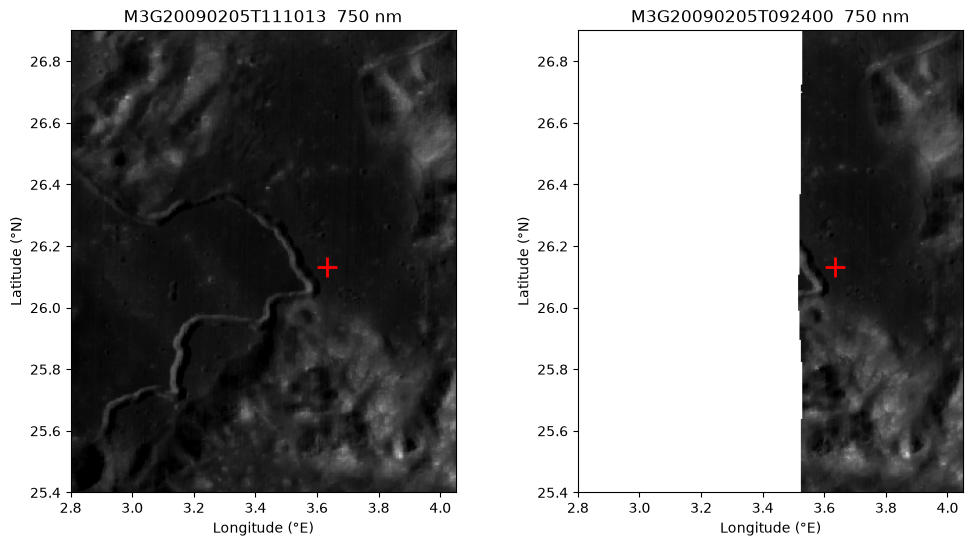

In [14]:
b = np.argmin(np.abs(wl - 750))                      # ~750 nm band
fig, axes = plt.subplots(1, len(subsets), figsize=(6 * len(subsets), 6), squeeze=False)
for ax, sub in zip(axes[0], subsets):
    ax.imshow(sub["rfl_geo"][b], cmap="gray",
              extent=(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX), vmin=0.03, vmax=0.20)
    ax.plot(SITE_LON, SITE_LAT, "r+", ms=14, mew=2)
    ax.set_title(f"{sub['strip']}  {wl[b]:.0f} nm")
    ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
plt.show()